# Experiment 3 — Breadth-first and depth-first search
CSAI4014 AISR Laboratory · Lab Manual, Chapter 4

The maze is an implicit graph: neighbours are computed on demand. One `search` function gives BFS or
DFS depending on which end of the deque is popped. We record the expansion order and the frontier size,
validate each path, and repeat on a second maze that has loops (several routes to the goal).

In [1]:
import json, os, platform, sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figs", exist_ok=True)
RESULTS = {}                      # every number the report quotes is stored here

def save(fig, name):
    """Save a figure into figs/ (150 dpi PNG, as the report guidelines ask)."""
    fig.savefig(os.path.join("figs", name), bbox_inches="tight")

def env_info():
    info = {"python": platform.python_version(), "numpy": np.__version__,
            "matplotlib": matplotlib.__version__, "os": f"{platform.system()} {platform.release()}",
            "cpu": platform.processor() or platform.machine()}
    try:
        import scipy; info["scipy"] = scipy.__version__
    except ImportError:
        pass
    return info

RESULTS["env"] = env_info()
print(RESULTS["env"])

{'python': '3.12.1', 'numpy': '2.3.2', 'matplotlib': '3.8.4', 'os': 'Windows 11', 'cpu': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'scipy': '1.16.1'}


## 1. The maze as an implicit graph

In [2]:
from collections import deque

# 1 = wall, 0 = open
MAZE = np.array([
    [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    [1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1],
    [1,0,1,0,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,0,1],
    [1,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,1],
    [1,1,1,1,1,0,1,0,1,0,1,0,1,1,1,1,1,0,1,0,1],
    [1,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,1,0,1,0,1],
    [1,0,1,0,1,0,1,0,1,0,1,1,1,1,1,0,1,0,1,0,1],
    [1,0,1,0,0,0,1,0,1,0,1,0,0,0,0,0,1,0,0,0,1],
    [1,0,1,1,1,1,1,0,1,0,1,0,1,1,1,1,1,1,1,0,1],
    [1,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1],
    [1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1],
    [1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1],
    [1,0,1,0,1,0,1,1,1,1,1,1,1,0,1,0,1,0,1,0,1],
    [1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1],
    [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1]
])

def neighbours(maze, cell):
    H, W = maze.shape
    r, c = cell
    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):   # up, down, left, right
        nr, nc = r + dr, c + dc
        if 0 <= nr < H and 0 <= nc < W:                 # BOUNDS FIRST
            if maze[nr, nc] == 0:                       # then contents
                yield (nr, nc)

H, W = MAZE.shape
START, GOAL = (1, 1), (H - 2, W - 2)
print(f"maze {H} x {W}, open cells = {int((MAZE == 0).sum())}, start {START}, goal {GOAL}")

maze 15 x 21, open cells = 139, start (1, 1), goal (13, 19)


## 2. One function, two algorithms

In [3]:
def search(maze, start, goal, mode="bfs"):
    frontier = deque([start])
    parent = {start: None}          # doubles as the explored set
    order = {}                      # cell -> the step at which it was expanded
    frontier_size = []              # frontier length at every expansion step
    while frontier:
        node = frontier.popleft() if mode == "bfs" else frontier.pop()
        # ^ THE ONLY DIFFERENCE BETWEEN THE TWO ALGORITHMS
        if node in order:
            continue
        order[node] = len(order)
        frontier_size.append(len(frontier))
        if node == goal:
            break
        for nxt in neighbours(maze, node):
            if nxt not in parent:   # mark on enqueue, not on expansion
                parent[nxt] = node
                frontier.append(nxt)
    path, cur = [], goal
    if goal in parent:
        while cur is not None:
            path.append(cur); cur = parent[cur]
    return order, path[::-1], frontier_size

def validate(maze, path, start, goal):
    """Every step adjacent (Manhattan distance 1) and no cell on a wall."""
    ok_ends = path[0] == start and path[-1] == goal
    ok_adj = all(abs(a[0]-b[0]) + abs(a[1]-b[1]) == 1 for a, b in zip(path, path[1:]))
    ok_wall = all(maze[r, c] == 0 for r, c in path)
    return ok_ends and ok_adj and ok_wall

res = {}
for mode in ("bfs", "dfs"):
    order, path, fsz = search(MAZE, START, GOAL, mode)
    res[mode] = (order, path, fsz)
    print(f"{mode.upper()}: {len(order)} expanded, path length {len(path)} cells "
          f"({len(path)-1} steps), max frontier {max(fsz)}, valid = {validate(MAZE, path, START, GOAL)}")
RESULTS["maze1"] = {"rows": H, "cols": W, "open": int((MAZE == 0).sum()),
    **{m: {"expanded": len(res[m][0]), "path_cells": len(res[m][1]), "steps": len(res[m][1]) - 1,
           "max_frontier": max(res[m][2]), "valid": validate(MAZE, res[m][1], START, GOAL)} for m in res}}
RESULTS["same_path"] = res["bfs"][1] == res["dfs"][1]
print("BFS and DFS return the identical path:", RESULTS["same_path"])

BFS: 137 expanded, path length 95 cells (94 steps), max frontier 2, valid = True
DFS: 105 expanded, path length 95 cells (94 steps), max frontier 3, valid = True
BFS and DFS return the identical path: True


## 3. Watching the expansion order and the frontier

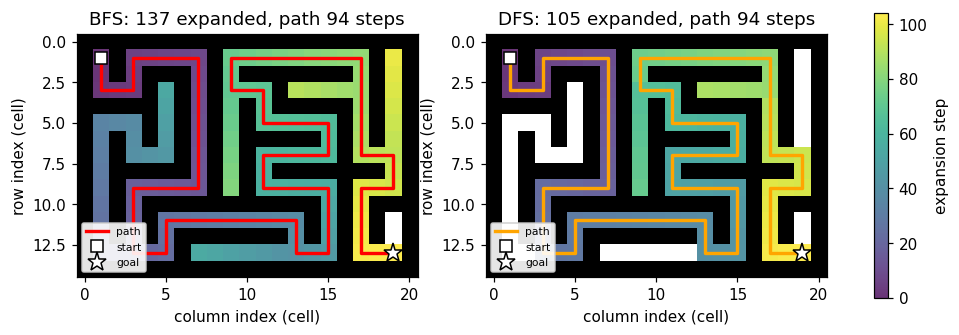

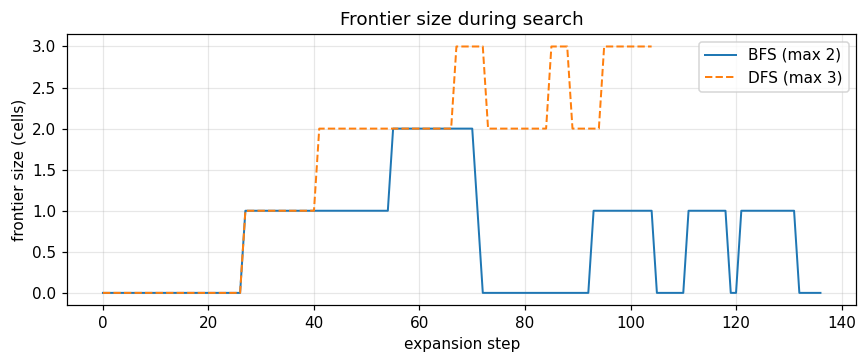

In [4]:
def draw(ax, maze, order, path, title, colour):
    grid = np.full(maze.shape, np.nan)            # nan = never expanded
    for (r, c), k in order.items():
        grid[r, c] = k                            # shade by expansion order
    ax.imshow(maze, cmap="binary")
    im = ax.imshow(grid, cmap="viridis", alpha=0.8)
    ax.plot([c for _, c in path], [r for r, _ in path], lw=2.2, color=colour, label="path")
    ax.plot(*START[::-1], "s", color="w", mec="k", ms=8, label="start")
    ax.plot(*GOAL[::-1], "*", color="w", mec="k", ms=13, label="goal")
    ax.set(title=title, xlabel="column index (cell)", ylabel="row index (cell)")
    ax.grid(False)
    return im

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, mode, col in zip(axes, ("bfs", "dfs"), ("red", "orange")):
    order, path, _ = res[mode]
    im = draw(ax, MAZE, order, path, f"{mode.upper()}: {len(order)} expanded, path {len(path)-1} steps", col)
    ax.legend(loc="lower left", fontsize=7, framealpha=0.9)
fig.colorbar(im, ax=axes, shrink=0.8, label="expansion step")
save(fig, "fig3_1_maze_paths.png"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.4))
for mode, ls in (("bfs", "-"), ("dfs", "--")):
    ax.plot(res[mode][2], ls, lw=1.3, label=f"{mode.upper()} (max {max(res[mode][2])})")
ax.set(xlabel="expansion step", ylabel="frontier size (cells)", title="Frontier size during search")
ax.legend()
fig.tight_layout(); save(fig, "fig3_2_frontier.png"); plt.show()

## 4. A second maze with loops
In the maze above every corridor is a dead end or the single route, so there is exactly one path to the goal
and BFS and DFS must return the same one. Opening a few walls creates alternative routes, which is where
the shortest-path guarantee of BFS becomes visible.

loopy maze BFS: 142 expanded, path 40 steps, valid = True
loopy maze DFS: 59 expanded, path 54 steps, valid = True


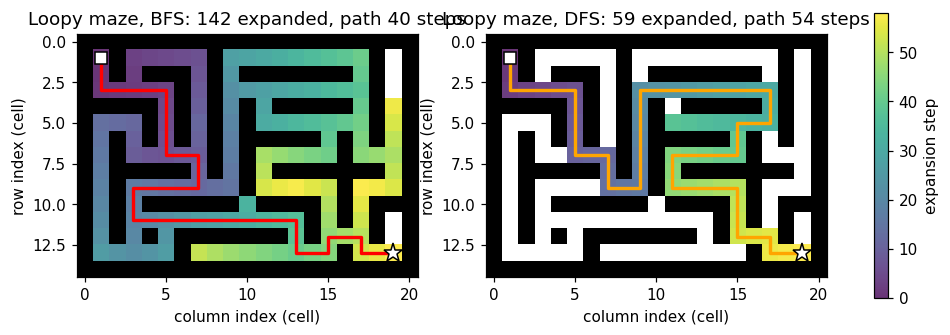

In [5]:
MAZE2 = MAZE.copy()
for r, c in [(3, 4), (7, 6), (9, 8), (11, 4), (5, 16), (12, 16), (3, 12), (10, 10)]:
    MAZE2[r, c] = 0                               # knock out eight interior walls
res2 = {m: search(MAZE2, START, GOAL, m) for m in ("bfs", "dfs")}
for m in res2:
    o, p, fsz = res2[m]
    print(f"loopy maze {m.upper()}: {len(o)} expanded, path {len(p)-1} steps, "
          f"valid = {validate(MAZE2, p, START, GOAL)}")
RESULTS["maze2"] = {m: {"expanded": len(res2[m][0]), "steps": len(res2[m][1]) - 1,
                        "valid": validate(MAZE2, res2[m][1], START, GOAL)} for m in res2}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, mode, col in zip(axes, ("bfs", "dfs"), ("red", "orange")):
    o, p, _ = res2[mode]
    im = draw(ax, MAZE2, o, p, f"Loopy maze, {mode.upper()}: {len(o)} expanded, path {len(p)-1} steps", col)
fig.colorbar(im, ax=axes, shrink=0.8, label="expansion step")
save(fig, "fig3_3_loopy_maze.png"); plt.show()

In [6]:
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print("saved results.json and", len(os.listdir("figs")), "figures in figs/")

saved results.json and 3 figures in figs/
